# Evaluate inner-lag and transport-delay limits on an outer position loop.

Run in a Python environment with OneSimulation 0.2.0, NumPy, SciPy and Matplotlib. Change the input data and rerun to compare with the saved reference output.

crossover 20 rad/s: delay-free pole margin = 28.543 /s, 6 ms phase margin = 71.81 deg
crossover 50 rad/s: delay-free pole margin = 50.000 /s, 6 ms phase margin = 46.25 deg


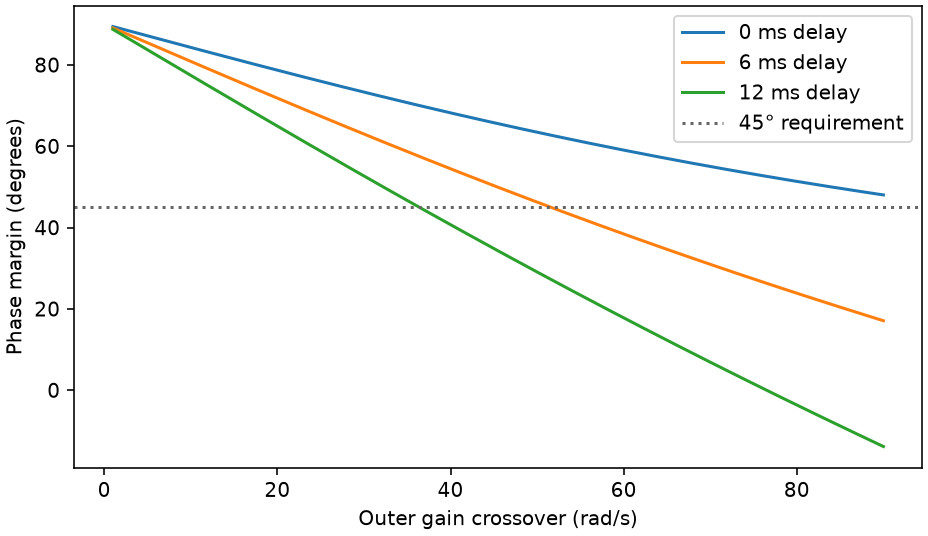

In [1]:
"""Evaluate inner-lag and transport-delay limits on an outer position loop."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.physics.systems.control import stability_margin

inner_pole = 100.0  # rad/s, achieved bandwidth of the closed speed loop
def outer_gain(crossover):
    return crossover*np.sqrt(1+(crossover/inner_pole)**2)
def phase_margin(crossover, delay):
    return 90-np.rad2deg(np.arctan(crossover/inner_pole)+crossover*delay)

frequencies = np.linspace(1,90,250)
fig, ax = plt.subplots(figsize=(6.4,3.7), layout="constrained")
for delay in [0.0,0.006,0.012]:
    ax.plot(frequencies, phase_margin(frequencies,delay),label=f"{1000*delay:.0f} ms delay")
for crossover in [20.0, 50.0]:
    gain = outer_gain(crossover)
    poles = np.roots([1.0,inner_pole,inner_pole*gain])
    print(f"crossover {crossover:.0f} rad/s: delay-free pole margin = "
          f"{stability_margin(poles,discrete=False):.3f} /s, "
          f"6 ms phase margin = {phase_margin(crossover,0.006):.2f} deg")
ax.axhline(45,color="0.4",ls=":",label="45° requirement")
ax.set(xlabel="Outer gain crossover (rad/s)",ylabel="Phase margin (degrees)")
ax.legend()
plt.show()
